# 04 — ผลที่รันจริง ปัญหาที่เห็น และขั้นถัดไป

บทนี้ไม่เลือกเฉพาะ run ที่ดูดี แต่ค้นทุก run ใน bulk artifact directory แล้วอ่าน `execution.json` และ metrics ที่มีอยู่จริง

หลักการอ่านผล:

- Accuracy ตอบว่าเดาถูกกี่ตัวอย่างโดยรวม
- Macro-F1 ให้น้ำหนักแต่ละคลาสเท่ากัน จึงเปิดโปงปัญหาคลาสเล็กได้ดีกว่า
- Confusion matrix บอกว่าโมเดลสับสนคลาสใดกับคลาสใด
- ผล cap128 มีประโยชน์เป็น integration/pilot evidence แต่ยังไม่ใช่คำตอบสุดท้ายทางวิจัย

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "paper_faithful").is_dir())
sys.path.insert(0, str(ROOT / "walkthrough"))

import matplotlib.pyplot as plt
import numpy as np
from walkthrough_lib import *

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
print(f"Project root : {PROJECT_ROOT}")
print(f"Bulk artifacts: {BULK_ROOT}")

Project root : C:\Users\Acer\OneDrive\Documents\เป้าๆรวยๆๆๆ\sleep_stage_reproduction
Bulk artifacts: E:\blp\sleep_stage_reproduction


## 1. Inventory ของ run ที่มี Stage 3 metrics

In [2]:
runs = discover_runs()
visible = []
for row in runs:
    visible.append({
        "revision": row["revision"],
        "seed": row["model_seed"],
        "status": row["status"],
        "cap": row["cap"],
        "accuracy": "—" if row["stage3_accuracy"] is None else f"{row['stage3_accuracy']:.3f}",
        "macro_f1": "—" if row["stage3_macro_f1"] is None else f"{row['stage3_macro_f1']:.3f}",
        "run_id": row["run_id"],
    })
print_records(visible, ["revision", "seed", "status", "cap", "accuracy", "macro_f1", "run_id"])

revision | seed | status    | cap | accuracy | macro_f1 | run_id                                                     
---------+------+-----------+-----+----------+----------+------------------------------------------------------------
r18      | 42   | completed | 128 | 0.406    | 0.214    | paper-text-v1-multiseed-cap128-r18-20260902-split42-model42
r18      | 43   | failed    | 128 | —        | —        | paper-text-v1-multiseed-cap128-r18-20260902-split43-model43
r19      | 42   | completed | 128 | 0.398    | 0.195    | paper-text-v1-multiseed-cap128-r19-20260905-split42-model42
r19      | 43   | completed | 128 | 0.219    | 0.147    | paper-text-v1-multiseed-cap128-r19-20260905-split43-model43
r9       | 42   | completed | 128 | 0.398    | 0.179    | paper-text-v1-multiseed-cap128-r9-20260828-split42-model42 
r9       | 43   | running   | 128 | —        | —        | paper-text-v1-multiseed-cap128-r9-20260828-split43-model43 
r3       | 42   | running   | 128 | —        | —        

## 2. เปรียบเทียบผล Stage 3 ที่มีจริง

เส้น 83% แสดงตำแหน่งตัวเลขที่บทความรายงานเพื่อให้เห็นเป้าหมายเท่านั้น **แท่ง pilot เหล่านี้ห้ามใช้เป็น direct replication comparison** เพราะ cap และ execution conditions ต่างกัน

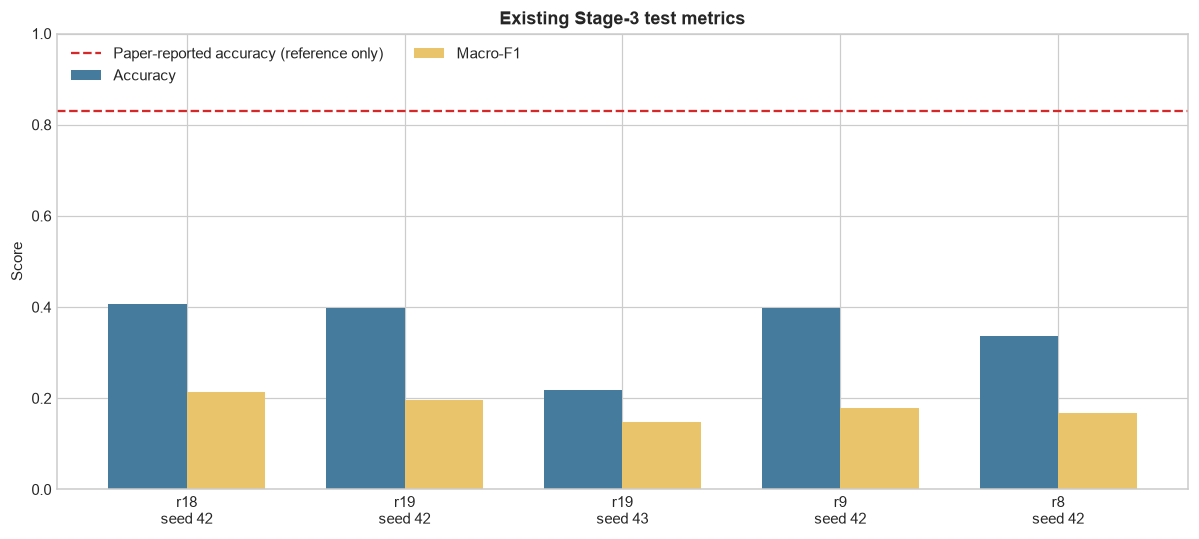

In [3]:
completed = [row for row in runs if row["stage3_accuracy"] is not None]
labels = [f"{row['revision']}\nseed {row['model_seed']}" for row in completed]
accuracy = [row["stage3_accuracy"] for row in completed]
macro_f1 = [row["stage3_macro_f1"] for row in completed]
x = np.arange(len(completed))

fig, ax = plt.subplots(figsize=(11, 5))
width = 0.36
ax.bar(x - width/2, accuracy, width, label="Accuracy", color="#457b9d")
ax.bar(x + width/2, macro_f1, width, label="Macro-F1", color="#e9c46a")
ax.axhline(0.83, color="#d62828", linestyle="--", label="Paper-reported accuracy (reference only)")
ax.set(xticks=x, xticklabels=labels, ylim=(0, 1), ylabel="Score", title="Existing Stage-3 test metrics")
ax.legend(loc="upper left", ncols=2)
plt.tight_layout()
plt.show()

## 3. เจาะ r19 สอง seed

r19 ทั้งสอง run จบครบ แต่ผลต่างกันและ macro-F1 ต่ำ แปลว่า pipeline ทำงานได้แต่โมเดลยังไม่จำแนกครบทุกคลาสใน pilot ขนาดเล็ก

C:\Users\Acer\AppData\Local\Temp\ipykernel_26544\3217521185.py:6: UserWarning: Glyph 3588 (\N{THAI CHARACTER KHO KHWAI}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Acer\AppData\Local\Temp\ipykernel_26544\3217521185.py:6: UserWarning: Glyph 3634 (\N{THAI CHARACTER SARA AA}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Acer\AppData\Local\Temp\ipykernel_26544\3217521185.py:6: UserWarning: Glyph 3607 (\N{THAI CHARACTER THO THAHAN}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Acer\AppData\Local\Temp\ipykernel_26544\3217521185.py:6: UserWarning: Glyph 3650 (\N{THAI CHARACTER SARA O}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Acer\AppData\Local\Temp\ipykernel_26544\3217521185.py:6: UserWarning: Glyph 3617 (\N{THAI CHARACTER MO MA}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Acer\AppData\Local\Temp\ipykernel_26544\3217521185.py:6: UserWarning: Glyph 3648 (\N{THAI CHARACTER SARA E}) missing from font(s) Arial.
  plt.tight_

C:\Users\Acer\OneDrive\Documents\เป้าๆรวยๆๆๆ\sleep_stage_reproduction\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3588 (\N{THAI CHARACTER KHO KHWAI}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Acer\OneDrive\Documents\เป้าๆรวยๆๆๆ\sleep_stage_reproduction\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3634 (\N{THAI CHARACTER SARA AA}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Acer\OneDrive\Documents\เป้าๆรวยๆๆๆ\sleep_stage_reproduction\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3592 (\N{THAI CHARACTER CHO CHAN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Acer\OneDrive\Documents\เป้าๆรวยๆๆๆ\sleep_stage_reproduction\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3619 (\N{THAI CHARACTER RO RUA}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:

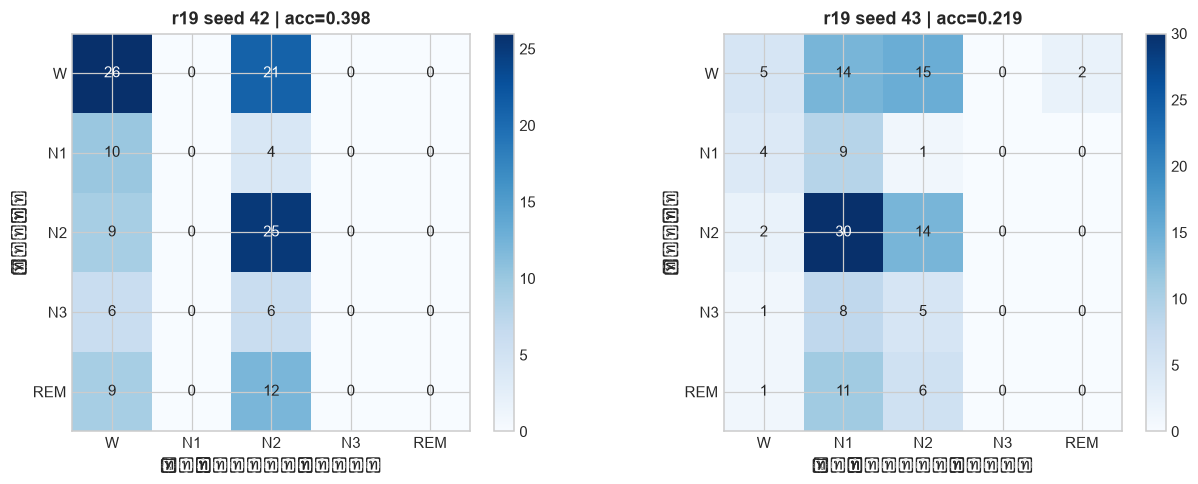

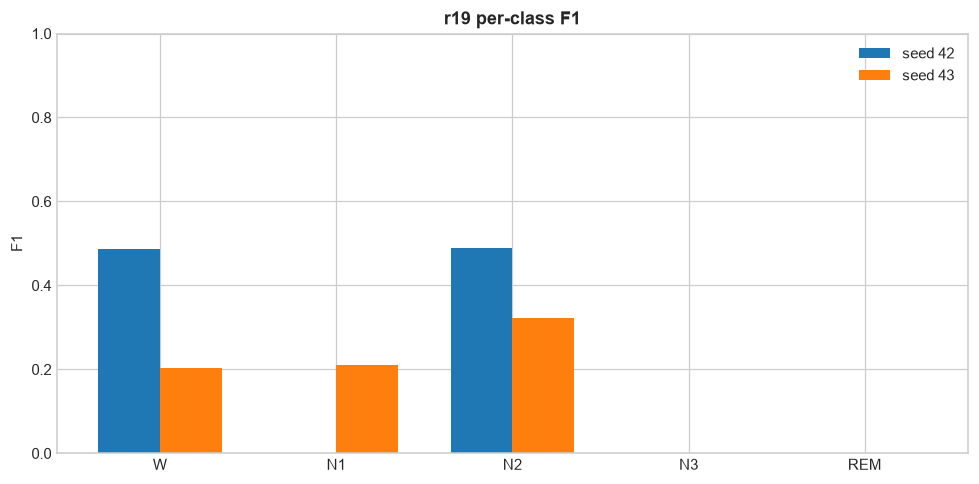

In [4]:
latest = r19_runs()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, row in zip(axes, latest):
    metrics = stage_metrics(row["path"], "stage3")
    plot_confusion_matrix(metrics["confusion_matrix"], f"r19 seed {row['model_seed']} | acc={metrics['accuracy']:.3f}", ax=ax)
plt.tight_layout()
plt.show()

per_class = {label: [] for label in LABELS}
for row in latest:
    metrics = stage_metrics(row["path"], "stage3")
    for label in LABELS:
        per_class[label].append(metrics["per_class_f1"][label])

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(LABELS))
for i, row in enumerate(latest):
    ax.bar(x + (i - 0.5) * 0.35, [per_class[label][i] for label in LABELS], 0.35, label=f"seed {row['model_seed']}")
ax.set(xticks=x, xticklabels=LABELS, ylim=(0, 1), ylabel="F1", title="r19 per-class F1")
ax.legend()
plt.tight_layout()
plt.show()

## 4. เหตุใด subject-generalization ยังไม่เริ่ม

เราเตรียม protocol 6 folds, test/review และ canonical gate แล้ว แต่ gate รอบล่าสุดตรวจพบ RAM ว่างต่ำกว่าเกณฑ์ 4,096 MB จึงปฏิเสธก่อนสร้าง production marker และก่อนเริ่ม training นี่เป็น failure แบบปลอดภัย ไม่ใช่ผลล้มเหลวของโมเดล

status  | fresh_launch_authorized | reason                                                              | available_memory_mb | required_memory_mb | training_started | markers_created
--------+-------------------------+---------------------------------------------------------------------+---------------------+--------------------+------------------+----------------
blocked | False                   | live resource gate refused: available physical memory below 4096 MB | 3502.5              | 4096.0             | False            | False          


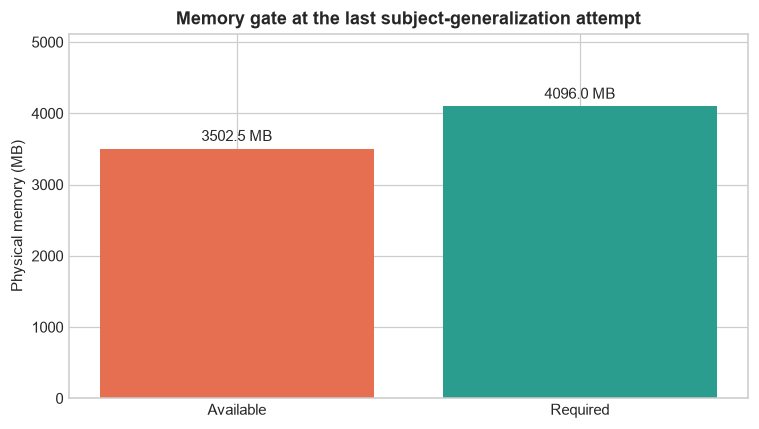

In [5]:
gate = subject_gate_summary()
print_records([gate])

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(["Available", "Required"], [gate["available_memory_mb"], gate["required_memory_mb"]], color=["#e76f51", "#2a9d8f"])
ax.bar_label(bars, fmt="%.1f MB", padding=3)
ax.set(title="Memory gate at the last subject-generalization attempt", ylabel="Physical memory (MB)")
ax.set_ylim(0, gate["required_memory_mb"] * 1.25)
plt.tight_layout()
plt.show()

## 5. แผนที่ควรทำต่อ

1. **รัน resource gate ใหม่เมื่อ RAM ว่างเพียงพอ** โดยใช้ fresh versioned run; ห้ามเปลี่ยนสถานะของหลักฐานเก่า
2. **ทำ subject-held-out pilot 6 folds** เพื่อวัดว่าทำนายคนที่ไม่เคยเห็นได้หรือไม่
3. **ตรวจแต่ละ fold แบบ standalone** แล้วรวมค่าเฉลี่ย/ส่วนเบี่ยงเบนพร้อม per-class F1
4. หาก pilot มีปัญหา ให้แยกว่าเกิดจาก data split, class imbalance, representation หรือ capacity ก่อนแก้
5. เมื่อ protocol และทรัพยากรนิ่ง จึงวางแผน **full numerical reproduction** ที่ไม่จำกัด cap128
6. รายงานสองคำถามแยกกัน: (ก) ทำซ้ำ protocol บทความได้แค่ไหน และ (ข) generalize ไปคนใหม่ได้แค่ไหน

### สถานะสั้นที่สุด

**ทำจริงมาแล้วมากกว่าตัวอย่างสาธิต:** full preprocessing + full SST cache + r19 สอง seed จบครบ แต่ผล cap128 ยังต่ำและ subject-held-out ยังไม่เริ่ม ดังนั้นโครงการ “เดินท่อครบแล้ว” แต่ยัง “ตอบคำถามวิจัยสุดท้ายไม่ครบ”